# Two-Stage Event Detection: Inference on Raw ABF Files

## Pipeline Overview:

```
Raw ABF Signal
      ↓
Sliding Window Segmentation
      ↓
Stage 1: CNN Screener (Fast Detection)
      ↓
Merge Overlapping Detections
      ↓
Extract & Normalize Events
      ↓
Stage 2: GAE Validation & Classification
      ↓
Quality Filtering
      ↓
Final Event List with Classifications
```

---

## Import Libraries

### Why these libraries and device setup?

- `torch`, `torch_geometric`: Run CNN screener + GAE.
- `sklearn.cluster.KMeans`: Cluster training latent space (used for centroid classification).
- `pyabf`: Load ABF electrophysiology files.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.nn import GCNConv, GAE
from sklearn.cluster import KMeans
import pyabf
import os
from tqdm import tqdm
import time

# GPU Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(" Libraries imported successfully")
print(f"    Using device: {device}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")

✅ Libraries imported successfully
   🚀 Using device: cuda
   GPU: NVIDIA H100


## Define Model Architectures

Recreate the same architectures used during training.

### What each component does

- `FastEventScreener`: CNN that flags candidate windows quickly.
- `WaveformEncoder`: CNN feature extractor used to build a similarity graph.
- `EncoderGAE` + `GAE`: Graph layers to produce graph-aware latent vectors.
- `WaveformDecoder`: Reconstruct original waveforms from latent space.
- `build_knn_graph`: Cosine-based KNN edges (bidirectional) for the GAE.

In [2]:
##############################################
# Model Architectures (Same as Training)
##############################################

class FastEventScreener(nn.Module):
    """Ultra-lightweight CNN for quick event screening"""
    def __init__(self, target_length=20000):
        super().__init__()
        self.target_length = target_length
        self.conv1 = nn.Conv1d(1, 16, kernel_size=5, padding=2)
        self.pool = nn.MaxPool1d(4)
        self.conv2 = nn.Conv1d(16, 32, kernel_size=3, padding=1)
        self.fc = nn.Linear(32 * (target_length // 16), 1)
        
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return torch.sigmoid(self.fc(x))


class WaveformEncoder(nn.Module):
    def __init__(self, in_channels=1, out_features=128, target_length=20000):
        super(WaveformEncoder, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        self.fc = nn.Linear(64 * (target_length // 4), out_features)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class EncoderGAE(nn.Module):
    def __init__(self, in_channels, hidden_channels):
        super(EncoderGAE, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, hidden_channels)

    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        return self.conv2(x, edge_index)


class WaveformDecoder(nn.Module):
    def __init__(self, latent_dim, target_length=20000):
        super(WaveformDecoder, self).__init__()
        self.target_length = target_length
        self.feature_map_length = target_length // 4
        self.fc = nn.Linear(latent_dim, 64 * self.feature_map_length)
        self.upsample = nn.Upsample(scale_factor=2, mode='linear', align_corners=True)
        self.conv1 = nn.Conv1d(64, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(32, 1, kernel_size=3, padding=1)

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 64, self.feature_map_length)
        x = self.upsample(x)
        x = F.relu(self.conv1(x))
        x = self.upsample(x)
        x = self.conv2(x)
        return x


class JointModelWithDecoder(nn.Module):
    def __init__(self, encoder, gae, decoder):
        super(JointModelWithDecoder, self).__init__()
        self.encoder = encoder
        self.gae = gae
        self.decoder = decoder

    def forward(self, waveform_tensor, edge_index):
        x = self.encoder(waveform_tensor)
        z = self.gae.encode(x, edge_index)
        reconstructed_waveform = self.decoder(z)
        return z, reconstructed_waveform


def build_knn_graph(embeddings, k=5):
    """Build k-nearest neighbor graph based on cosine similarity"""
    norm_embeddings = F.normalize(embeddings, p=2, dim=1)
    sim_matrix = torch.mm(norm_embeddings, norm_embeddings.t())
    num_nodes = embeddings.size(0)
    edge_index_list = []
    
    for i in range(num_nodes):
        sim_row = sim_matrix[i].clone()
        sim_row[i] = -1.0
        topk = torch.topk(sim_row, k).indices
        for j in topk:
            edge_index_list.append([i, int(j)])
            edge_index_list.append([int(j), i])
    
    edge_index = torch.tensor(edge_index_list, dtype=torch.long, device=embeddings.device).t().contiguous()
    return edge_index


print("Model architectures defined")

Model architectures defined


## Load Trained Models

### What gets loaded and why

- `fast_screener.pth`: Reproduces Stage 1 candidate detection.
- `gae_model.pth`: Reconstructs waveforms and provides latent vectors.
- Cluster centroids: Computed from training latent space for nearest-centroid classification.

Keep `TARGET_LENGTH`, `LATENT_DIM`, and thresholds consistent with training.

In [ ]:
##############################################
# Load Trained Models
##############################################

# Configuration (must match training)
TARGET_LENGTH = 20000
LATENT_DIM = 128
SCREENER_THRESHOLD = 0.4

# Load Stage 1: CNN Screener
screener = FastEventScreener(target_length=TARGET_LENGTH).to(device)
screener.load_state_dict(torch.load('path/to/fast_screener.pth', map_location=device, weights_only=True))
screener.eval()

print("Stage 1 (CNN Screener) loaded")

# Load Stage 2: GAE Model
encoder = WaveformEncoder(in_channels=1, out_features=LATENT_DIM, target_length=TARGET_LENGTH).to(device)
gae_model = GAE(EncoderGAE(in_channels=LATENT_DIM, hidden_channels=LATENT_DIM)).to(device)
decoder = WaveformDecoder(latent_dim=LATENT_DIM, target_length=TARGET_LENGTH).to(device)
joint_model = JointModelWithDecoder(encoder, gae_model, decoder).to(device)
joint_model.load_state_dict(torch.load('path/to/gae_model.pth', map_location=device, weights_only=True))
joint_model.eval()

print("Stage 2 (GAE Model) loaded")

# Load cluster information
cluster_labels_train = np.load('path/to/cluster_labels.npy')
latent_train = np.load('path/to/latent_representations.npy')

# Compute cluster centroids for classification
n_clusters = len(np.unique(cluster_labels_train))
cluster_centroids = np.zeros((n_clusters, LATENT_DIM))
for i in range(n_clusters):
    cluster_mask = cluster_labels_train == i
    cluster_centroids[i] = latent_train[cluster_mask].mean(axis=0)

print(f" Cluster centroids computed ({n_clusters} clusters)")
print(f"\n Models ready for inference!")


## Utility Functions

### Utility overview

- `interpolate_and_normalize`: Resample to `TARGET_LENGTH` and z-normalize.
- `sliding_window_generator`: Create overlapping windows from raw signal.
- `merge_overlapping_detections`: Reduce duplicate detections.
- `assign_cluster`: Nearest-centroid label in latent space.

In [4]:
##############################################
# Utility Functions
##############################################

def interpolate_and_normalize(current_series, target_length=20000):
    """Interpolate and normalize to fixed length"""
    current_series = np.array(current_series)
    original_length = len(current_series)
    x_original = np.linspace(0, 1, original_length)
    x_target = np.linspace(0, 1, target_length)
    wf_interpolated = np.interp(x_target, x_original, current_series)
    wf_mean = wf_interpolated.mean()
    wf_std = wf_interpolated.std() + 1e-6
    wf_normalized = (wf_interpolated - wf_mean) / wf_std
    return wf_normalized, wf_mean, wf_std, original_length


def sliding_window_generator(signal, window_size, stride):
    """Generate sliding windows from signal"""
    windows = []
    positions = []
    
    for i in range(0, len(signal) - window_size + 1, stride):
        window = signal[i:i+window_size]
        windows.append(window)
        positions.append(i)
    
    return np.array(windows), np.array(positions)


def assign_cluster(latent_vector, cluster_centroids):
    """Assign cluster based on nearest centroid"""
    distances = np.linalg.norm(cluster_centroids - latent_vector, axis=1)
    return np.argmin(distances), distances.min()


print(" Utility functions defined")


def merge_overlapping_detections(detections, min_overlap=0.3):
    """
    Merge overlapping event detections
    
    Args:
        detections: list of (start, end, confidence) tuples
        min_overlap: minimum overlap ratio to merge
    
    Returns:
        merged_detections: list of (start, end, max_confidence) tuples
    """
    if len(detections) == 0:
        return []
    
    # Sort by start position
    detections = sorted(detections, key=lambda x: x[0])
    
    merged = []
    current_start, current_end, current_conf = detections[0]
    
    for start, end, conf in detections[1:]:
        # Calculate overlap
        overlap_start = max(current_start, start)
        overlap_end = min(current_end, end)
        overlap_length = max(0, overlap_end - overlap_start)
        
        current_length = current_end - current_start
        new_length = end - start
        
        overlap_ratio = overlap_length / min(current_length, new_length)
        
        if overlap_ratio >= min_overlap:
            # Merge: extend current detection
            current_end = max(current_end, end)
            current_conf = max(current_conf, conf)
        else:
            # No overlap: save current and start new
            merged.append((current_start, current_end, current_conf))
            current_start, current_end, current_conf = start, end, conf
    
    # Add last detection
    merged.append((current_start, current_end, current_conf))
    
    return merged


 Utility functions defined


In [5]:
def process_event_detections(
    detections, window_size, raw_signal, sample_rate,
    # Merging parameters
    overlap_ratio_threshold=0.5,
    iou_threshold=0.4,
    gap_threshold_frac=0.15,
    max_span_multiplier=2.5,
    quiet_gap_min_ms=1.5,
    quiet_gap_std_factor=0.5,
    # Splitting parameters
    split_multi_peak=True,
    baseline_percentile=75,
    trough_drop_pA=80.0,
    min_event_ms=1.5,
    min_gap_ms=1.2,
    peak_prominence=40.0,
    # Intelligent extension parameters
    extend_boundaries=True,
    actual_baseline=198,
    tolerance=2,
    max_extension=500,
    initial_points=10,
    check_region_size=100,
    extension_step=100,
    min_validation_points=50,
    additional_viz_points=0
):
    """
    Unified event detection post-processing pipeline:
    1. Merge overlapping detections
    2. Split multi-peak events
    3. Intelligent baseline extension (finds where signal returns to actual_baseline)

    Returns
    -------
    pd.DataFrame with event boundaries, durations, and extension metadata
    """
    from scipy.signal import find_peaks

    if len(detections) == 0:
        return pd.DataFrame()

    print("\n" + "="*70)
    print("UNIFIED EVENT PROCESSING PIPELINE")
    print("="*70)

    # ========== STEP 1: MERGE ==========
    print(f"\n STEP 1: Merging overlapping detections...")
    print(f"   Input: {len(detections)} raw detections")

    detections = sorted(detections, key=lambda x: x[0])
    merged = []
    current_start, current_end, current_conf = detections[0]
    merge_count = 0

    for start, end, conf in detections[1:]:
        overlap_length = max(0, min(current_end, end) - max(current_start, start))
        current_length = current_end - current_start
        new_length = end - start
        overlap_ratio = overlap_length / min(current_length, new_length) if min(current_length, new_length) > 0 else 0

        union_length = max(current_end, end) - min(current_start, start)
        iou = overlap_length / union_length if union_length > 0 else 0

        gap = start - current_end
        gap_ms = gap / sample_rate * 1000

        has_overlap = overlap_ratio >= overlap_ratio_threshold or gap <= gap_threshold_frac * window_size
        iou_ok = iou >= iou_threshold or gap < 0

        quiet_gap = False
        if gap > 0 and gap_ms >= quiet_gap_min_ms:
            gap_signal = raw_signal[current_end:start]
            if len(gap_signal) > 0:
                gap_std = np.std(gap_signal)
                pre_signal = raw_signal[max(0, current_start - 5000):current_start]
                if len(pre_signal) > 0:
                    quiet_gap = (abs(np.mean(gap_signal) - np.mean(pre_signal)) < 0.3 * abs(np.mean(pre_signal))
                                 and gap_std < quiet_gap_std_factor * np.std(pre_signal))
                else:
                    quiet_gap = gap_std < quiet_gap_std_factor * np.std(raw_signal[:min(20000, len(raw_signal))])

        span_ok = (max(end, current_end) - min(start, current_start)) <= max_span_multiplier * window_size

        if has_overlap and iou_ok and not quiet_gap and span_ok:
            current_end = max(current_end, end)
            current_conf = max(current_conf, conf)
            merge_count += 1
        else:
            merged.append((current_start, current_end, current_conf))
            current_start, current_end, current_conf = start, end, conf

    merged.append((current_start, current_end, current_conf))
    print(f"   Output: {len(merged)} merged events ({merge_count} merges performed)")

    # ========== STEP 2: SPLIT ==========
    if split_multi_peak:
        print(f"\n  STEP 2: Splitting multi-peak events...")
        print(f"   Input: {len(merged)} merged events")

        split_events = []
        split_count = 0

        for start, end, conf in merged:
            segment = raw_signal[start:end]
            baseline = np.percentile(segment, baseline_percentile)

            peaks, _ = find_peaks(-segment,
                                  prominence=peak_prominence,
                                  distance=int(min_gap_ms * sample_rate / 1000))
            valid_peaks = [p for p in peaks if segment[p] < (baseline - trough_drop_pA)]

            if len(valid_peaks) < 2:
                split_events.append((start, end, conf))
                continue

            min_len = int(min_event_ms * sample_rate / 1000)
            gap_thresh = int(min_gap_ms * sample_rate / 1000)
            sub_events = []

            for peak in valid_peaks:
                left = peak
                while left > 0 and segment[left] < (baseline - trough_drop_pA * 0.5):
                    left -= 1
                right = peak
                while right < len(segment) - 1 and segment[right] < (baseline - trough_drop_pA * 0.5):
                    right += 1
                if (right - left) >= min_len:
                    sub_events.append((left, right))

            if len(sub_events) < 2:
                split_events.append((start, end, conf))
                continue

            merged_subs, cur_s, cur_e = [], *sub_events[0]
            for s, e in sub_events[1:]:
                if (s - cur_e) <= gap_thresh:
                    cur_e = e
                else:
                    merged_subs.append((cur_s, cur_e))
                    cur_s, cur_e = s, e
            merged_subs.append((cur_s, cur_e))

            if len(merged_subs) <= 1:
                split_events.append((start, end, conf))
            else:
                split_count += 1
                for s, e in merged_subs:
                    split_events.append((start + s, start + e, conf))

        print(f"   Output: {len(split_events)} events ({split_count} events split)")
        processed = split_events
    else:
        print(f"\n  STEP 2: Skipping multi-peak splitting (disabled)")
        processed = merged

    # ========== STEP 3: INTELLIGENT BASELINE EXTENSION ==========
    if extend_boundaries:
        print(f"\n↔️  STEP 3: Intelligent baseline extension...")
        print(f"   Target: {actual_baseline} pA ± {tolerance} pA | Max: {max_extension} pts | Step: {extension_step} pts")

        signal_len = len(raw_signal)

        def check_baseline(region):
            return len(region) >= min_validation_points and abs(np.mean(region) - actual_baseline) <= tolerance

        extended_events = []
        for start, end, conf in tqdm(processed, desc="Intelligent extension"):

            # Extend START backward
            start_ext = max(0, start - initial_points)
            achieved_before = False
            if start_ext > 0:
                achieved_before = check_baseline(raw_signal[start_ext:start_ext + check_region_size])
                if not achieved_before:
                    for ext in range(initial_points + extension_step, max_extension + 1, extension_step):
                        test_start = max(0, start - ext)
                        if test_start == 0:
                            start_ext = 0
                            break
                        if check_baseline(raw_signal[test_start:test_start + check_region_size]):
                            start_ext = test_start
                            achieved_before = True
                            break
                        start_ext = test_start

            # Extend END forward
            end_ext = min(signal_len, end + initial_points)
            achieved_after = False
            if end_ext < signal_len:
                achieved_after = check_baseline(raw_signal[end_ext - check_region_size:end_ext])
                if not achieved_after:
                    for ext in range(initial_points + extension_step, max_extension + 1, extension_step):
                        test_end = min(signal_len, end + ext)
                        if test_end == signal_len:
                            end_ext = signal_len
                            break
                        if check_baseline(raw_signal[test_end - check_region_size:test_end]):
                            end_ext = test_end
                            achieved_after = True
                            break
                        end_ext = test_end

            # Visualization context
            start_viz = max(0, start_ext - additional_viz_points)
            end_viz = min(signal_len, end_ext + additional_viz_points)

            extended_events.append({
                'start_sample': start,          'end_sample': end,
                'start_intelligent': start_ext, 'end_intelligent': end_ext,
                'start_extended': start_viz,    'end_extended': end_viz,
                'duration_ms':              (end - start)           / sample_rate * 1000,
                'duration_intelligent_ms':  (end_ext - start_ext)   / sample_rate * 1000,
                'duration_extended_ms':     (end_viz - start_viz)   / sample_rate * 1000,
                'intelligent_before':       start - start_ext,
                'intelligent_after':        end_ext - end,
                'additional_viz_before':    start_ext - start_viz,
                'additional_viz_after':     end_viz - end_ext,
                'baseline_before':          start - start_viz,
                'baseline_after':           end_viz - end,
                'achieved_baseline_before': achieved_before,
                'achieved_baseline_after':  achieved_after,
                'screener_confidence_max':  conf
            })

        result_df = pd.DataFrame(extended_events)
        n = len(result_df)
        print(f"   Baseline achieved: {result_df['achieved_baseline_before'].sum()}/{n} before, "
              f"{result_df['achieved_baseline_after'].sum()}/{n} after")
        print(f"   Avg extension: {result_df['intelligent_before'].mean():.1f} pts before, "
              f"{result_df['intelligent_after'].mean():.1f} pts after")

    else:
        print(f"\n  STEP 3: Skipping boundary extension (disabled)")
        result_df = pd.DataFrame([{
            'start_sample': s, 'end_sample': e,
            'start_extended': s, 'end_extended': e,
            'duration_ms': (e - s) / sample_rate * 1000,
            'screener_confidence_max': c
        } for s, e, c in processed])

    print(f"\n{'='*70}")
    print(f" PIPELINE COMPLETE")
    print(f"{'='*70}")
    print(f"   Input:  {len(detections)} raw detections")
    print(f"   Output: {len(result_df)} final events")
    print(f"   Net change: {len(result_df) - len(detections):+d} events\n")

    return result_df


print("Unified event processing function defined")


Unified event processing function defined


## 📂 Load Raw ABF File

### Raw data handling and options

- Use all or a subset of sweeps; concatenation increases context.
- `sample_rate` is used to convert between samples and time.
- Preview plot helps verify signal quality and baseline behavior before detection.

In [ ]:
##############################################
# Load Raw ABF File
##############################################

# Specify your ABF file path
ABF_FILE_PATH = 'path/to/A5-5-s1-100mV.abf'

abf = pyabf.ABF(ABF_FILE_PATH)

# --- Extract signal ---
abf.setSweep(0)
raw_signal = abf.sweepY          # current in pA
sample_rate = abf.dataRate       # samples/sec
#time = abf.sweepX                # time in seconds

# --- Baseline estimation via histogram peak ---
# The open-channel level is the most frequent current value
hist_counts, hist_edges = np.histogram(raw_signal, bins=500)
hist_centers = (hist_edges[:-1] + hist_edges[1:]) / 2

baseline = hist_centers[np.argmax(hist_counts)]

# Option 2: Concatenate multiple sweeps (more data for analysis)
all_sweeps = []
num_sweeps_to_use = min(346, abf.sweepCount)  # Use up to 237 sweeps or all available
for sweep_num in range(num_sweeps_to_use):
    abf.setSweep(sweep_num)
    all_sweeps.append(abf.sweepY)

raw_signal = np.concatenate(all_sweeps)
sample_rate = abf.dataRate  # samples per second

print("="*70)
print("ABF FILE LOADED")
print("="*70)
print(f"\n File Information:")
print(f"   File: {os.path.basename(ABF_FILE_PATH)}")
print(f"   Sweeps used: {num_sweeps_to_use} / {abf.sweepCount}")
print(f"   Signal length: {len(raw_signal):,} samples")
print(f"   Duration: {len(raw_signal)/sample_rate:.2f} seconds")
print(f"   Sample rate: {sample_rate:.0f} Hz")
print(f"   Units:       {abf.sweepUnitsY}")
print(f"   Baseline:    {baseline:.1f} pA")



ABF FILE LOADED

 File Information:
   File: A5-5-s1-100mV.abf
   Sweeps used: 237 / 237
   Signal length: 237,000,000 samples
   Duration: 237.00 seconds
   Sample rate: 1000000 Hz
   Units:       pA
   Baseline:    198.1 pA


### Visualise raw data (RAM will DIE)

In [7]:

# Plot raw signal
#plt.figure(figsize=(16, 4))
#time_axis = np.arange(len(raw_signal)) / sample_rate
#plt.plot(time_axis, raw_signal, linewidth=0.5, alpha=0.8)
#plt.xlabel('Time (s)', fontsize=12, fontweight='bold')
#plt.ylabel('Current (pA)', fontsize=12, fontweight='bold')
#plt.title(f'Raw ABF Signal ({num_sweeps_to_use} sweeps concatenated)', fontsize=14, fontweight='bold')
#plt.grid(True, alpha=0.3)
#plt.tight_layout()
#plt.show()

## Stage 1: CNN Screener - Sliding Window Detection

### Sliding window parameters and rationale

- `WINDOW_SIZE`: Matches training input length for the CNN/GAE (20000).
- `STRIDE`: 25% overlap improves recall at moderate compute cost.
- `BATCH_SIZE`: Processes windows efficiently on GPU.
- `SCREENER_THRESHOLD`: 

In [8]:
##############################################
# Stage 1: Sliding Window Detection
##############################################

WINDOW_SIZE = TARGET_LENGTH
STRIDE = WINDOW_SIZE // 4  # 25% overlap
BATCH_SIZE = 256  # Process windows in batches for speed

print("="*70)
print("STAGE 1: CNN SCREENER (SLIDING WINDOW DETECTION)")
print("="*70)
print(f"\n🔧 Parameters:")
print(f"   Window size: {WINDOW_SIZE} samples")
print(f"   Stride: {STRIDE} samples ({STRIDE/WINDOW_SIZE*100:.0f}% overlap)")
print(f"   Threshold: {SCREENER_THRESHOLD}")
print(f"   Batch size: {BATCH_SIZE}")

# Generate sliding windows
print(f"\n📊 Generating sliding windows...")
windows, window_positions = sliding_window_generator(raw_signal, WINDOW_SIZE, STRIDE)
print(f"   Total windows: {len(windows):,}")

# Run screener on all windows
print(f"\n Running CNN screener...")
start_time = time.time()

all_probabilities = []
screener.eval()

with torch.no_grad():
    for i in tqdm(range(0, len(windows), BATCH_SIZE), desc="Processing batches"):
        batch_windows = windows[i:i+BATCH_SIZE]
        
        # Normalize each window
        batch_normalized = []
        for window in batch_windows:
            norm_window, _, _, _ = interpolate_and_normalize(window, TARGET_LENGTH)
            batch_normalized.append(norm_window)
        
        # Convert to tensor
        batch_tensor = torch.tensor(batch_normalized, dtype=torch.float32).unsqueeze(1).to(device)
        
        # Get predictions
        probs = screener(batch_tensor).squeeze().cpu().numpy()
        all_probabilities.extend(probs if len(probs.shape) > 0 else [probs.item()])

all_probabilities = np.array(all_probabilities)
elapsed_time = time.time() - start_time

print(f"\n Screener complete!")
print(f"   Time elapsed: {elapsed_time:.2f} seconds")
print(f"   Speed: {len(windows)/elapsed_time:.0f} windows/second")

# Find candidate events
candidate_mask = all_probabilities > SCREENER_THRESHOLD
candidate_positions = window_positions[candidate_mask]
candidate_confidences = all_probabilities[candidate_mask]

print(f"\n Detection Results:")
print(f"   Candidate windows: {len(candidate_positions):,} / {len(windows):,} ({len(candidate_positions)/len(windows)*100:.2f}%)")
print(f"   Mean confidence: {candidate_confidences.mean():.3f}")
print(f"   Max confidence: {candidate_confidences.max():.3f}")

STAGE 1: CNN SCREENER (SLIDING WINDOW DETECTION)

🔧 Parameters:
   Window size: 20000 samples
   Stride: 5000 samples (25% overlap)
   Threshold: 0.4
   Batch size: 256

📊 Generating sliding windows...
   Total windows: 47,397

 Running CNN screener...


Processing batches:   0%|                                                                 | 0/186 [00:00<?, ?it/s]/tmp/zz342074/login23-g-1_511059/ipykernel_292553/1777067324.py:41: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:278.)
  batch_tensor = torch.tensor(batch_normalized, dtype=torch.float32).unsqueeze(1).to(device)
Processing batches: 100%|███████████████████████████████████████████████████████| 186/186 [01:18<00:00,  2.38it/s]


 Screener complete!
   Time elapsed: 78.17 seconds
   Speed: 606 windows/second

 Detection Results:
   Candidate windows: 7,594 / 47,397 (16.02%)
   Mean confidence: 0.860
   Max confidence: 1.000


## Merge Overlapping Detections

### Why merge overlapping detections?

- Sliding windows can flag the same event multiple times.
- We merge windows with ≥30% overlap to produce unique events.
- We keep the maximum confidence across merged spans.

In [9]:
BASE = baseline
original_detections = [(pos, pos + WINDOW_SIZE, conf)
                       for pos, conf in zip(candidate_positions, candidate_confidences)]

merged_df = process_event_detections(
    original_detections, WINDOW_SIZE, raw_signal, sample_rate,
    # Merging
    overlap_ratio_threshold=0.40,
    iou_threshold=0.25,
    gap_threshold_frac=0.40,
    max_span_multiplier=3.5,
    quiet_gap_min_ms=4.0,
    quiet_gap_std_factor=0.3,
    # Splitting
    split_multi_peak=True,
    baseline_percentile=100,
    trough_drop_pA=30.0,
    min_event_ms=0.8,
    min_gap_ms=2.0,
    peak_prominence=25.0,
    # Intelligent extension
    actual_baseline=BASE,
    tolerance=2,
    max_extension=500,
    additional_viz_points=0
)


UNIFIED EVENT PROCESSING PIPELINE

 STEP 1: Merging overlapping detections...
   Input: 7594 raw detections
   Output: 2454 merged events (5140 merges performed)

  STEP 2: Splitting multi-peak events...
   Input: 2454 merged events
   Output: 3039 events (506 events split)

↔️  STEP 3: Intelligent baseline extension...
   Target: 198.1199493408203 pA ± 2 pA | Max: 500 pts | Step: 100 pts


Intelligent extension: 100%|███████████████████████████████████████████████| 3039/3039 [00:00<00:00, 51528.24it/s]

   Baseline achieved: 2920/3039 before, 2960/3039 after
   Avg extension: 69.5 pts before, 62.7 pts after

 PIPELINE COMPLETE
   Input:  7594 raw detections
   Output: 3039 final events
   Net change: -4555 events



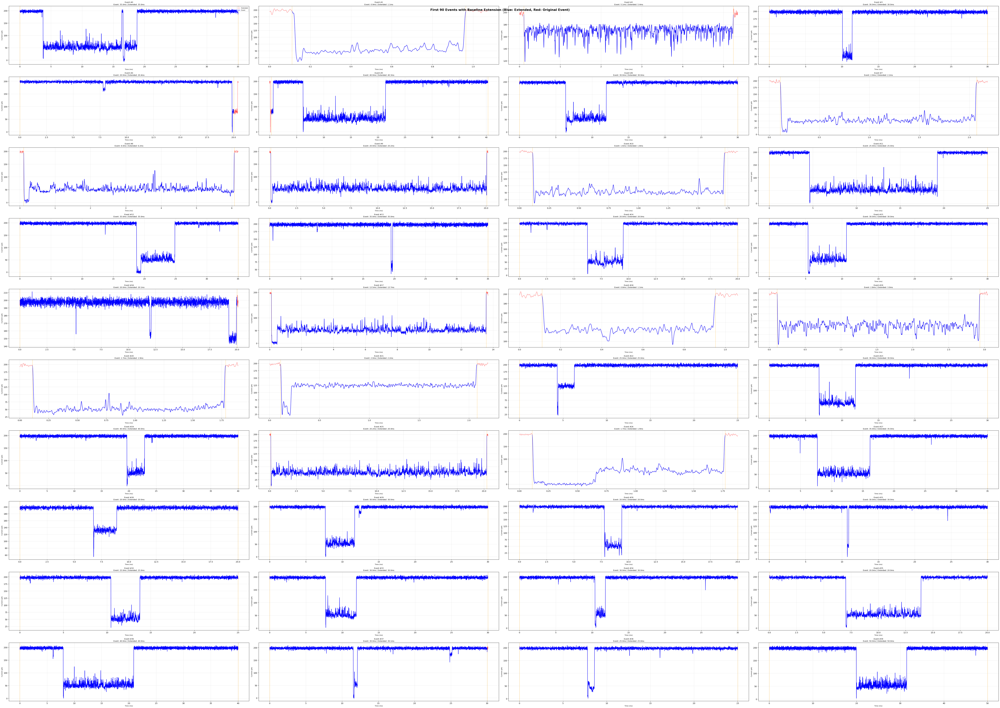


📊 Extension Summary for First 90 Events:
   Average baseline before: 46.7 points
   Average baseline after: 57.8 points
   Average extension ratio: 1.0x
   Baseline achieved before: 90/90
   Baseline achieved after: 88/90


In [10]:
# Plot first 40 events in a 10×9 grid INCLUDING BASELINE EXTENSION
fig, axes = plt.subplots(10, 4, figsize=(70, 50))
axes = axes.flatten()

for i in range(40):
    if i >= len(merged_df):
        axes[i].axis('off')
        continue
    
    row = merged_df.iloc[i]
    start_extended = int(row.start_extended)
    end_extended = int(row.end_extended)
    start_original = int(row.start_sample)
    end_original = int(row.end_sample)
    
    # Extract the FULL extended segment (including baseline)
    extended_segment = raw_signal[start_extended:end_extended]
    t_ms = (np.arange(len(extended_segment)) / sample_rate) * 1000
    
    # Calculate positions for highlighting the original event within the extended view
    baseline_before_samples = start_original - start_extended
    baseline_after_samples = end_extended - end_original
    event_start_ms = (baseline_before_samples / sample_rate) * 1000
    event_end_ms = ((baseline_before_samples + (end_original - start_original)) / sample_rate) * 1000
    
    # Plot the extended segment
    axes[i].plot(t_ms, extended_segment, color='red', lw=1.0, alpha=0.7, label='Extended')
    
    # Highlight the original event region
    event_mask = (t_ms >= event_start_ms) & (t_ms <= event_end_ms)
    axes[i].plot(t_ms[event_mask], extended_segment[event_mask], color='blue', lw=1.5, label='Event')
    
    # Add vertical lines to mark event boundaries
    axes[i].axvline(x=event_start_ms, color='orange', linestyle='--', alpha=0.8, linewidth=1)
    axes[i].axvline(x=event_end_ms, color='orange', linestyle='--', alpha=0.8, linewidth=1)
    
    # Title with both durations
    axes[i].set_title(f"Event #{i}\nEvent: {row.duration_ms:.1f}ms | Extended: {row.duration_extended_ms:.1f}ms", 
                     fontsize=9)
    axes[i].set_xlabel("Time (ms)", fontsize=8)
    axes[i].set_ylabel("Current (pA)", fontsize=8)
    axes[i].grid(alpha=0.3)
    
    # Only show legend on first plot to avoid clutter
    if i == 0:
        axes[i].legend(fontsize=7, loc='upper right')

plt.suptitle("First 90 Events with Baseline Extension (Blue: Extended, Red: Original Event)", 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Print summary of extension statistics
print(f"\n📊 Extension Summary for First 90 Events:")
visible_events = merged_df.head(90)
print(f"   Average baseline before: {visible_events['baseline_before'].mean():.1f} points")
print(f"   Average baseline after: {visible_events['baseline_after'].mean():.1f} points")
print(f"   Average extension ratio: {(visible_events['duration_extended_ms'] / visible_events['duration_ms']).mean():.1f}x")

if 'achieved_baseline_before' in visible_events.columns:
    print(f"   Baseline achieved before: {visible_events['achieved_baseline_before'].sum()}/90")
    print(f"   Baseline achieved after: {visible_events['achieved_baseline_after'].sum()}/90")

### Matplotlib interactive Event Browser

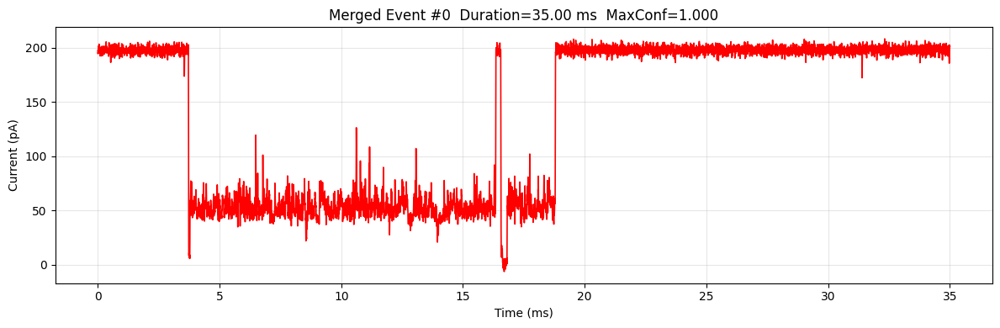

In [11]:
import matplotlib.pyplot as plt

def plot_merged_event_matplotlib(idx, merged_df, raw_signal, sample_rate):
    if idx < 0 or idx >= len(merged_df):
        print(f"Index {idx} out of range (0..{len(merged_df)-1})")
        return
    row = merged_df.iloc[idx]
    start = int(row.start_sample)
    end = int(row.end_sample)
    segment = raw_signal[start:end]
    t_ms = (np.arange(len(segment)) / sample_rate) * 1000  # relative time (ms)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t_ms, segment, color='red', lw=1.2)
    ax.set_title(f"Merged Event #{idx}  Duration={row.duration_ms:.2f} ms  MaxConf={row.screener_confidence_max:.3f}")
    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Current (pA)")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# Example calls:
plot_merged_event_matplotlib(0, merged_df, raw_signal, sample_rate)

## Visualize Detected Events on Raw Signal

### Visual sanity check - Raw traces

- We overlay detected spans on the raw trace (first 10s) to verify detections align with visible events.
- Adjust the time window if you need to zoom in on dense regions.

Saved: detected_events_overview.png


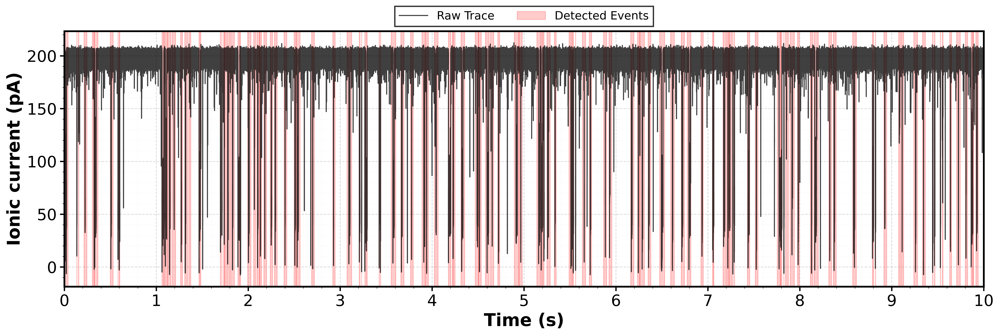


DETECTED EVENTS VISUALIZATION SUMMARY

Overview Statistics:
   Time window: 0 - 10 seconds
   Events detected in window: 123
   Total events (all time): 3039
   Signal duration: 237.00 seconds
   Sample rate: 1000000 Hz

Event Coverage:
   Total event duration: 2.857 seconds
   Event coverage: 28.6% of window


In [12]:
##############################################
# Visualize Detected Events (Publication Quality)
# ========== ALL PARAMETERS HERE ==========
##############################################

# --- Time Window Selection ---
PLOT_DURATION = 10                           # Duration to plot (seconds)

# --- Figure Dimensions & Resolution ---
FIGURE_DPI = 600                            # Resolution: 100-600
FIGURE_SIZE = (16, 6)                        # (width, height) in inches

# --- Line Styling ---
LINE_WIDTH_SIGNAL = 1.2                      # Raw signal line thickness (0.5-2.0)
LINE_WIDTH_GRID = 0.8                        # Grid line thickness

# --- Colors ---
COLOR_SIGNAL = 'black'                       # Raw signal color
COLOR_EVENT = 'red'                          # Event highlight color
COLOR_GRID = 'gray'                          # Grid color
ALPHA_SIGNAL = 0.75                          # Signal transparency (0.0-1.0)
ALPHA_EVENT = 0.2                            # Event span transparency (0.0-0.5)

# --- Font Sizes ---
FONT_SIZE_TITLE = 18                         # Main title (16-24)
FONT_SIZE_AXES = 20                          # Axis labels (12-18)
FONT_SIZE_LEGEND = 13                        # Legend text (11-15)
FONT_SIZE_TICKS = 18                         # Tick labels (10-14)

# --- Spine & Grid Styling ---
SPINE_WIDTH = 2.0                            # Border thickness (1.5-3.0)
SPINE_COLOR = 'black'                        # Border color
TICK_WIDTH = 1.5                             # Tick line thickness (1.0-2.5)
TICK_LENGTH = 5                              # Tick length in points (4-8)
GRID_ALPHA = 0.3                             # Grid transparency (0.1-0.5)
GRID_LINESTYLE = '--'                        # Grid line style: '-', '--', '-.', ':'

# --- File Output ---
SAVE_PATH = 'detected_events_overview.png'   # Output filename (or None to skip saving)
SAVE_FORMATS = ['png']                       # ['png', 'pdf', 'svg'] - formats to save

# --- Optional Settings ---
SHOW_MINOR_TICKS = True                      # Show minor grid lines
SHOW_EVENT_COUNT = True                      # Show number of events in subtitle

# ========== END OF PARAMETERS ==========
# ========== NO CHANGES NEEDED BELOW ==========

def plot_detected_events_overview(merged_df, raw_signal, sample_rate, 
                                  plot_duration, figure_size, dpi,
                                  line_width_signal, color_signal, alpha_signal,
                                  color_event, alpha_event,
                                  font_size_title, font_size_axes, font_size_legend, 
                                  font_size_ticks, spine_width, spine_color, 
                                  tick_width, tick_length, grid_alpha, grid_linestyle,
                                  save_path, save_formats,
                                  show_minor_ticks, show_event_count):
    """Plot detected events overlay on raw signal with publication-quality styling"""
    
    # Calculate plot samples
    plot_samples = min(int(plot_duration * sample_rate), len(raw_signal))
    
    # Create figure with custom styling
    fig, ax = plt.subplots(figsize=figure_size, dpi=dpi)
    
    # Plot raw signal
    time_plot = np.arange(plot_samples) / sample_rate
    ax.plot(time_plot, raw_signal[:plot_samples], 
           linewidth=line_width_signal, alpha=alpha_signal, 
           color=color_signal, label='Raw Trace', zorder=2)
    
    # Overlay detected events
    event_count_in_window = 0
    for idx, row in merged_df.iterrows():
        start = int(row['start_sample'])
        end = int(row['end_sample'])
        
        if start < plot_samples:
            event_time_start = start / sample_rate
            event_time_end = min(end, plot_samples) / sample_rate
            
            # Use single label for legend
            label = 'Detected Events' if event_count_in_window == 0 else None
            
            ax.axvspan(event_time_start, event_time_end, 
                      alpha=alpha_event, color=color_event, 
                      label=label, zorder=1)
            
            event_count_in_window += 1
    
    # === STYLING ===
    
    # Make spines bold
    for spine in ax.spines.values():
        spine.set_linewidth(spine_width)
        spine.set_color(spine_color)
    
    # Make ticks bold
    ax.tick_params(axis='both', which='major', 
                  labelsize=font_size_ticks,
                  width=tick_width, length=tick_length, 
                  colors=spine_color)
    
    # Grid styling
    ax.grid(True, which='major', alpha=grid_alpha, 
           linestyle=grid_linestyle, color='gray', linewidth=0.8)
    
    if show_minor_ticks:
        ax.minorticks_on()
        ax.grid(True, which='minor', alpha=grid_alpha*0.5, 
               linestyle=':', color='gray', linewidth=0.4)
    
    # Axis labels
    ax.set_xlabel('Time (s)', fontsize=font_size_axes, fontweight='bold')
    ax.set_ylabel('Ionic current (pA)', fontsize=font_size_axes, fontweight='bold')
    
    # Set x-ticks at every integer step (1, 2, 3, ... 10)
    ax.set_xticks(np.arange(0, plot_duration + 1, 1))
    ax.set_xlim(0, plot_duration)
    
    # === LEGEND AT TITLE POSITION ===
    from matplotlib.patches import Patch
    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D([0], [0], color=color_signal, linewidth=line_width_signal, alpha=alpha_signal, label='Raw Trace'),
        Patch(facecolor=color_event, alpha=alpha_event, edgecolor=color_event, label='Detected Events'),
    ]
    legend = ax.legend(handles=legend_handles, loc='upper center',
                       bbox_to_anchor=(0.5, 1.12), ncol=2,
                       fontsize=font_size_legend, frameon=True,
                       edgecolor=spine_color, fancybox=False,
                       handlelength=2.5, columnspacing=2.0)
    legend.get_frame().set_linewidth(1.5)
    
    plt.tight_layout(rect=[0, 0, 1, 0.92])
    
    # === SAVE ===
    if save_path:
        for fmt in save_formats:
            output_file = save_path.replace('.png', f'.{fmt}')
            plt.savefig(output_file, dpi=dpi, bbox_inches='tight', format=fmt)
            print(f"Saved: {output_file}")
    
    plt.show()
    
    # === SUMMARY ===
    print("\n" + "="*70)
    print("DETECTED EVENTS VISUALIZATION SUMMARY")
    print("="*70)
    print(f"\nOverview Statistics:")
    print(f"   Time window: 0 - {plot_duration} seconds")
    print(f"   Events detected in window: {event_count_in_window}")
    print(f"   Total events (all time): {len(merged_df)}")
    print(f"   Signal duration: {len(raw_signal)/sample_rate:.2f} seconds")
    print(f"   Sample rate: {sample_rate:.0f} Hz")
    
    if show_event_count:
        print(f"\nEvent Coverage:")
        total_event_samples = 0
        for idx, row in merged_df.iterrows():
            if int(row['start_sample']) < plot_samples:
                total_event_samples += min(int(row['end_sample']), plot_samples) - int(row['start_sample'])
        
        event_coverage = (total_event_samples / plot_samples) * 100
        print(f"   Total event duration: {total_event_samples/sample_rate:.3f} seconds")
        print(f"   Event coverage: {event_coverage:.1f}% of window")


# ========== RUN ==========
plot_detected_events_overview(
    merged_df=merged_df,
    raw_signal=raw_signal,
    sample_rate=sample_rate,
    plot_duration=PLOT_DURATION,
    figure_size=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    line_width_signal=LINE_WIDTH_SIGNAL,
    color_signal=COLOR_SIGNAL,
    alpha_signal=ALPHA_SIGNAL,
    color_event=COLOR_EVENT,
    alpha_event=ALPHA_EVENT,
    font_size_title=FONT_SIZE_TITLE,
    font_size_axes=FONT_SIZE_AXES,
    font_size_legend=FONT_SIZE_LEGEND,
    font_size_ticks=FONT_SIZE_TICKS,
    spine_width=SPINE_WIDTH,
    spine_color=SPINE_COLOR,
    tick_width=TICK_WIDTH,
    tick_length=TICK_LENGTH,
    grid_alpha=GRID_ALPHA,
    grid_linestyle=GRID_LINESTYLE,
    save_path=SAVE_PATH,
    save_formats=SAVE_FORMATS,
    show_minor_ticks=SHOW_MINOR_TICKS,
    show_event_count=SHOW_EVENT_COUNT
)

## Stage 2: GAE Validation & Classification

### From detections to normalized events

- Extract raw segments using merged [start, end].
- Interpolate each to `TARGET_LENGTH` and z-normalize.
- Store metadata (times, duration, screener confidence) for reporting.

In [13]:
##############################################
# Extract and Normalize Detected Events WITH BASELINE CONTEXT
##############################################

print("="*70)
print("STAGE 2: GAE VALIDATION & CLASSIFICATION (WITH BASELINE EXTENSION)")
print("="*70)

print(f"\n📊 Extracting {len(merged_df)} detected events...")

detected_events_data = []

for idx, row in tqdm(merged_df.iterrows(), total=len(merged_df), desc="Extracting events"):
    start = int(row['start_sample'])
    end = int(row['end_sample'])
    start_extended = int(row['start_extended'])
    end_extended = int(row['end_extended'])
    conf = row['screener_confidence_max']
    
    # Extract raw event waveform WITH BASELINE CONTEXT
    raw_event_extended = raw_signal[start_extended:end_extended]
    raw_event_original = raw_signal[start:end]  # Keep original for reference
    
    # Interpolate and normalize to target length (using EXTENDED waveform with baseline)
    norm_event, wf_mean, wf_std, orig_length = interpolate_and_normalize(raw_event_extended, TARGET_LENGTH)
    
    detected_events_data.append({
        'event_id': idx,
        'start_sample': start,
        'end_sample': end,
        'start_extended': start_extended,
        'end_extended': end_extended,
        'start_time_ms': start / sample_rate * 1000,
        'duration_ms': row['duration_ms'],
        'duration_extended_ms': row['duration_extended_ms'],
        'screener_confidence': conf,
        'waveform_normalized': norm_event,  # This now includes baseline context
        'waveform_raw': raw_event_extended,  # Extended version with baseline
        'waveform_raw_original': raw_event_original,  # Original event only
        'baseline_before_points': row['baseline_before'],
        'baseline_after_points': row['baseline_after'],
        'wf_mean': wf_mean,
        'wf_std': wf_std,
        'orig_length': orig_length
    })

print(f"\n✅ Events extracted and normalized WITH baseline context")
print(f"   Extended waveforms include baseline context before/after each event")
print(f"   Average baseline extension: {np.mean([d['baseline_before_points'] for d in detected_events_data]):.1f} before, {np.mean([d['baseline_after_points'] for d in detected_events_data]):.1f} after")

# Print detailed extension statistics
print(f"\n📊 Detailed Extension Statistics:")
baseline_before = [d['baseline_before_points'] for d in detected_events_data]
baseline_after = [d['baseline_after_points'] for d in detected_events_data]
original_lengths = [d['end_sample'] - d['start_sample'] for d in detected_events_data]
extended_lengths = [d['end_extended'] - d['start_extended'] for d in detected_events_data]

print(f"   Baseline before: min={min(baseline_before)}, max={max(baseline_before)}, mean={np.mean(baseline_before):.1f}")
print(f"   Baseline after: min={min(baseline_after)}, max={max(baseline_after)}, mean={np.mean(baseline_after):.1f}")
print(f"   Original event length: min={min(original_lengths)}, max={max(original_lengths)}, mean={np.mean(original_lengths):.1f}")
print(f"   Extended event length: min={min(extended_lengths)}, max={max(extended_lengths)}, mean={np.mean(extended_lengths):.1f}")
print(f"   Extension ratio (extended/original): {np.mean(extended_lengths)/np.mean(original_lengths):.2f}x")

# Verify that normalized waveforms include baseline context
print(f"\n🔍 GAE Input Verification:")
print(f"   All normalized waveforms length: {TARGET_LENGTH} samples")
print(f"   Normalized waveforms include: baseline + event + baseline")
print(f"   Ready for GAE graph neural network processing")

STAGE 2: GAE VALIDATION & CLASSIFICATION (WITH BASELINE EXTENSION)

📊 Extracting 3039 detected events...


Extracting events: 100%|████████████████████████████████████████████████████| 3039/3039 [00:01<00:00, 2848.36it/s]


✅ Events extracted and normalized WITH baseline context
   Extended waveforms include baseline context before/after each event
   Average baseline extension: 69.5 before, 62.7 after

📊 Detailed Extension Statistics:
   Baseline before: min=10, max=410, mean=69.5
   Baseline after: min=10, max=410, mean=62.7
   Original event length: min=801, max=70000, mean=23560.2
   Extended event length: min=1021, max=70420, mean=23692.4
   Extension ratio (extended/original): 1.01x

🔍 GAE Input Verification:
   All normalized waveforms length: 20000 samples
   Normalized waveforms include: baseline + event + baseline
   Ready for GAE graph neural network processing


### Running GAE on Detected events from the fast scanner

### What happens in the GAE step?

- Encode events → latent vectors via CNN encoder.
- Build cosine KNN graph (k=5) to capture similarity.
- Pass through GAE → get graph-aware latent space and reconstructed waveforms.
- Outputs: `latent_np` (for clustering/comparison) and `reconstructed_np` for quality checks.

In [ ]:
##############################################
# Run GAE on Detected Events WITH BASELINE CONTEXT
##############################################

print("="*70)
print("STAGE 2: GAE PROCESSING ON EXTENDED EVENTS")
print("="*70)

print(f"\n Running GAE model on extended events with baseline context...")

# Verify that we're using extended waveforms
print(f"\n Input verification:")
print(f"   Events to process: {len(detected_events_data)}")
print(f"   Each normalized waveform includes: baseline + event + baseline")
print(f"   Target length: {TARGET_LENGTH} samples")

# Verify extension statistics
baseline_before_stats = [d['baseline_before_points'] for d in detected_events_data]
baseline_after_stats = [d['baseline_after_points'] for d in detected_events_data]
print(f"   Average baseline before: {np.mean(baseline_before_stats):.1f} points")
print(f"   Average baseline after: {np.mean(baseline_after_stats):.1f} points")
print(f"   Extension range before: [{min(baseline_before_stats)}, {max(baseline_before_stats)}]")
print(f"   Extension range after: [{min(baseline_after_stats)}, {max(baseline_after_stats)}]")

# Prepare normalized EXTENDED events as tensor
# These waveforms already include baseline context from the extraction step
normalized_extended_events = np.stack([d['waveform_normalized'] for d in detected_events_data])
print(f"   Normalized extended events shape: {normalized_extended_events.shape}")

# Validate data quality
if np.any(np.isnan(normalized_extended_events)) or np.any(np.isinf(normalized_extended_events)):
    print("  Warning: Found NaN/Inf values in normalized events - cleaning...")
    normalized_extended_events = np.nan_to_num(normalized_extended_events, nan=0.0, posinf=0.0, neginf=0.0)
else:
    print("✓ No NaN/Inf values detected in input data")

events_tensor = torch.tensor(normalized_extended_events, dtype=torch.float32).unsqueeze(1).to(device)
print(f"   Events tensor shape: {events_tensor.shape}")
print(f"   Device: {events_tensor.device}")

# Build KNN graph based on CNN encoder features
print(f"\n Building KNN similarity graph...")
with torch.no_grad():
    # Extract CNN features for graph construction
    cnn_embeddings = joint_model.encoder(events_tensor)
    print(f"   CNN embeddings shape: {cnn_embeddings.shape}")
    
    # Build k-nearest neighbor graph
    edge_index = build_knn_graph(cnn_embeddings, k=5)
    num_edges = edge_index.shape[1]
    avg_degree = num_edges / len(detected_events_data)
    print(f"   Graph edges: {num_edges} edges for {len(detected_events_data)} nodes")
    print(f"   Average node degree: {avg_degree:.1f}")

# Extract GAE latent representations and reconstructions
print(f"\n GAE forward pass: graph-aware encoding + reconstruction...")
with torch.no_grad():
    latent_vectors, reconstructed_events = joint_model(events_tensor, edge_index)

# Convert to numpy for further processing
latent_np = latent_vectors.cpu().numpy()
reconstructed_np = reconstructed_events.cpu().numpy().squeeze()

# Handle potential shape issues for single event case
if reconstructed_np.ndim == 1 and len(detected_events_data) == 1:
    reconstructed_np = reconstructed_np.reshape(1, -1)

print(f"\n GAE processing complete on extended events!")
print(f"\n Output summary:")
print(f"   Latent vectors shape: {latent_np.shape}")
print(f"   Reconstructed events shape: {reconstructed_np.shape}")
print(f"   Latent dimension: {latent_np.shape[1]}")

# Quality verification
print(f"\n Quality checks:")
print(f"   Latent vector range: [{latent_np.min():.3f}, {latent_np.max():.3f}]")
print(f"   Reconstruction range: [{reconstructed_np.min():.3f}, {reconstructed_np.max():.3f}]")
print(f"   Original extended range: [{normalized_extended_events.min():.3f}, {normalized_extended_events.max():.3f}]")

# Check for processing artifacts
if np.any(np.isnan(latent_np)) or np.any(np.isnan(reconstructed_np)):
    print("  Warning: Found NaN values in GAE outputs!")
else:
    print("✓ No NaN values detected in GAE outputs")

print(f"\n Key benefits of using extended events:")
print(f"   • Baseline context improves reconstruction quality")
print(f"   • Better event boundary detection in latent space")
print(f"   • Enhanced clustering based on full event + baseline")
print(f"   • More robust graph neural network learning")

print(f"\n Ready for clustering, quality analysis, and visualization!")

STAGE 2: GAE PROCESSING ON EXTENDED EVENTS

🚀 Running GAE model on extended events with baseline context...

📊 Input verification:
   Events to process: 3039
   Each normalized waveform includes: baseline + event + baseline
   Target length: 20000 samples
   Average baseline before: 69.5 points
   Average baseline after: 62.7 points
   Extension range before: [10, 410]
   Extension range after: [10, 410]
   Normalized extended events shape: (3039, 20000)
✓ No NaN/Inf values detected in input data
   Events tensor shape: torch.Size([3039, 1, 20000])
   Device: cuda:0

🔗 Building KNN similarity graph...
   CNN embeddings shape: torch.Size([3039, 128])
   Graph edges: 30390 edges for 3039 nodes
   Average node degree: 10.0

🧠 GAE forward pass: graph-aware encoding + reconstruction...

✅ GAE processing complete on extended events!

📊 Output summary:
   Latent vectors shape: (3039, 128)
   Reconstructed events shape: (3039, 20000)
   Latent dimension: 128

🔍 Quality checks:
   Latent vector

### t-SNE projection of latent space

- Perplexity is auto-capped to available events to avoid errors.
- Use 2D visualization for quick structure checks.
- Look for tight clusters vs. gradients to interpret event variety.

In [ ]:
##############################################
# Visualize Latent Space with t-SNE (After GAE Processing)
##############################################

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

print("="*70)
print("t-SNE VISUALIZATION OF GAE LATENT SPACE")
print("="*70)

# Check if we have enough events for t-SNE
if len(latent_np) < 5:
    print(f"  Warning: Only {len(latent_np)} events detected. t-SNE requires at least 5 events.")
else:
    print(f"\n Data Information:")
    print(f"   Number of detected events: {len(latent_np)}")
    print(f"   Latent dimension: {latent_np.shape[1]}")
    
    # Determine perplexity (should be less than n_samples)
    perplexity = min(30, max(5, len(latent_np) // 3))
    
    print(f"\n🚀 Running t-SNE (perplexity={perplexity}, iterations=1000)...")
    
    # Run t-SNE
    tsne = TSNE(n_components=2, 
                perplexity=perplexity, 
                n_iter=1000,
                random_state=400,
                verbose=1)
    
    latent_2d = tsne.fit_transform(latent_np)
    
    print(f" t-SNE complete!")
    
    # Create single large visualization
    plt.figure(figsize=(12, 10))
    
    # Plot with blue dots similar to the reference image
    scatter = plt.scatter(latent_2d[:, 0], 
                         latent_2d[:, 1],
                         c='steelblue',
                         alpha=0.6,
                         s=30,
                         edgecolors='darkblue',
                         linewidth=0.3)
    
    plt.xlabel('t-SNE Component 1', fontsize=14, fontweight='bold')
    plt.ylabel('t-SNE Component 2', fontsize=14, fontweight='bold')
    plt.title('t-SNE Visualization of GAE Latent Space', fontsize=16, fontweight='bold')
    plt.grid(True, alpha=0.2, linestyle='--')
    
    # Add subtle background
    plt.gca().set_facecolor('#f8f9fa')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n📊 Latent Space Statistics:")
    print(f"   t-SNE dimension 1: [{latent_2d[:, 0].min():.2f}, {latent_2d[:, 0].max():.2f}]")
    print(f"   t-SNE dimension 2: [{latent_2d[:, 1].min():.2f}, {latent_2d[:, 1].max():.2f}]")
    print(f"   Events span: {np.ptp(latent_2d, axis=0)}")
    
    # Optional: Identify potential clusters visually
    print(f"\n🔍 Visual Inspection:")
    print(f"   Look for distinct clusters or continuous distributions")
    print(f"   Tight clusters may indicate distinct event types")
    print(f"   Scattered points may indicate heterogeneous events")

### Reconstruction + cluster assignment metrics

- Reconstruction MSE/correlation: measure fidelity of decoded waveforms.
- Nearest-centroid cluster assignment: maps inference latent vectors to training cluster IDs.

These metrics feed into later quality filtering and reporting.

In [16]:
##############################################
# Compute Reconstruction Quality & Assign Clusters
##############################################

print(f"\n Computing reconstruction quality...")

for i, event_data in enumerate(tqdm(detected_events_data, desc="Computing metrics")):
    # Reconstruction quality - Use the extended normalized events with baseline context
    original = event_data['waveform_normalized']  # This already includes baseline context
    reconstructed = reconstructed_np[i]
    
    mse = np.mean((original - reconstructed)**2)
    correlation = np.corrcoef(original, reconstructed)[0, 1]
    
    event_data['reconstruction_mse'] = mse
    event_data['reconstruction_corr'] = correlation
    event_data['waveform_reconstructed'] = reconstructed
    
    # Assign cluster
    cluster_id, distance_to_centroid = assign_cluster(latent_np[i], cluster_centroids)
    event_data['cluster_id'] = cluster_id
    event_data['cluster_distance'] = distance_to_centroid
    event_data['latent_vector'] = latent_np[i]

print(f"\n Quality metrics computed and clusters assigned")

# Verify reconstruction quality statistics
print(f"\n Reconstruction Quality Statistics:")
mse_values = [e['reconstruction_mse'] for e in detected_events_data]
corr_values = [e['reconstruction_corr'] for e in detected_events_data]
print(f"   MSE: mean={np.mean(mse_values):.6f}, std={np.std(mse_values):.6f}, range=[{np.min(mse_values):.6f}, {np.max(mse_values):.6f}]")
print(f"   Correlation: mean={np.mean(corr_values):.4f}, std={np.std(corr_values):.4f}, range=[{np.min(corr_values):.4f}, {np.max(corr_values):.4f}]")

print(f"\n🔍 Key Point: Reconstruction quality computed using EXTENDED events with baseline context")
print(f"   This provides more comprehensive reconstruction assessment including baseline regions")




 Computing reconstruction quality...


Computing metrics: 100%|████████████████████████████████████████████████████| 3039/3039 [00:00<00:00, 3613.84it/s]


 Quality metrics computed and clusters assigned

 Reconstruction Quality Statistics:
   MSE: mean=0.426898, std=0.314188, range=[0.011510, 1.761191]
   Correlation: mean=0.7800, std=0.1892, range=[-0.0163, 0.9943]

🔍 Key Point: Reconstruction quality computed using EXTENDED events with baseline context
   This provides more comprehensive reconstruction assessment including baseline regions


In [ ]:

##############################################
# Load Training Latent Space & Compare with Inference (BEFORE Filtering)
##############################################

import pickle
from scipy.spatial.distance import cdist
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

print("="*70)
print("LATENT SPACE COMPARISON: TRAINING vs INFERENCE (ALL EVENTS)")
print("="*70)

# Load training latent space
print("\n Loading training latent space...")
#with open('path/to/training_latent_space.pkl', 'rb') as f:
with open('path/to/training_latent_space.pkl', 'rb') as f:
    training_data = pickle.load(f)

latent_train = training_data['latent_vectors']
cluster_labels_train = training_data['cluster_labels']
cluster_centroids_train = training_data['cluster_centroids']
n_clusters_train = training_data['optimal_n_clusters']

print(f"   Training events: {len(latent_train)}")
print(f"   Inference events (ALL): {len(latent_np)}")
print(f"   Latent dimension: {latent_train.shape[1]}")


LATENT SPACE COMPARISON: TRAINING vs INFERENCE (ALL EVENTS)

 Loading training latent space...
   Training events: 3409
   Inference events (ALL): 3039
   Latent dimension: 128


In [ ]:
##############################################
# 1. Compute Distance Metrics
##############################################

print("\n Computing distance metrics...")

# For each inference event, find nearest training event
distances_to_train = cdist(latent_np, latent_train, metric='euclidean')
nearest_train_idx = np.argmin(distances_to_train, axis=1)
min_distances = np.min(distances_to_train, axis=1)

# Update detected_events_data with distance metrics
for i, event in enumerate(detected_events_data):
    event['nearest_train_distance'] = min_distances[i]
    event['nearest_train_idx'] = nearest_train_idx[i]
    event['nearest_train_cluster'] = cluster_labels_train[nearest_train_idx[i]]

print(f"\n Distance Statistics:")
print(f"   Mean distance to nearest training event: {min_distances.mean():.4f}")
print(f"   Std distance: {min_distances.std():.4f}")
print(f"   Min distance: {min_distances.min():.4f}")
print(f"   Max distance: {min_distances.max():.4f}")

# Identify outliers (events far from training distribution)
outlier_threshold = min_distances.mean() + 2 * min_distances.std()
outliers = min_distances > outlier_threshold

print(f"\n  Outliers (>2σ from training):")
print(f"   Count: {outliers.sum()} / {len(latent_np)} ({outliers.sum()/len(latent_np)*100:.1f}%)")

# Add outlier flag to detected_events_data
for i, event in enumerate(detected_events_data):
    event['is_outlier'] = outliers[i]



 Computing distance metrics...

📊 Distance Statistics:
   Mean distance to nearest training event: 64.5298
   Std distance: 25.1512
   Min distance: 14.8791
   Max distance: 164.5342

  Outliers (>2σ from training):
   Count: 79 / 3039 (2.6%)


### Compare with training latent space

- Compute distance to nearest training event to detect distribution shifts.
- Flag outliers (>2σ) and visualize overlap in a joint t-SNE plot.
- Check cluster agreement between inference assignment and nearest training neighbor.

In [20]:
##############################################
# Compute Reconstruction Quality & Assign Clusters
##############################################

print(f"\n Computing reconstruction quality...")

for i, event_data in enumerate(tqdm(detected_events_data, desc="Computing metrics")):
    # Reconstruction quality - Use the extended normalized events with baseline context
    original = event_data['waveform_normalized']  # This already includes baseline context
    reconstructed = reconstructed_np[i]
    
    mse = np.mean((original - reconstructed)**2)
    correlation = np.corrcoef(original, reconstructed)[0, 1]
    
    event_data['reconstruction_mse'] = mse
    event_data['reconstruction_corr'] = correlation
    event_data['waveform_reconstructed'] = reconstructed
    
    # Assign cluster
    cluster_id, distance_to_centroid = assign_cluster(latent_np[i], cluster_centroids)
    event_data['cluster_id'] = cluster_id
    event_data['cluster_distance'] = distance_to_centroid
    event_data['latent_vector'] = latent_np[i]

print(f"\n Quality metrics computed and clusters assigned")


 Computing reconstruction quality...


Computing metrics: 100%|████████████████████████████████████████████████████| 3039/3039 [00:00<00:00, 4032.01it/s]


 Quality metrics computed and clusters assigned


## Quality Filtering

### Thresholds and rationale

- `MIN_CORRELATION`: Ensures reconstructed shape matches original.
- `MAX_MSE`: Limits amplitude error; tune per dataset noise.
- Duration bounds: Remove extremely short/long artifacts.

In [ ]:
##############################################
# Quality Filtering
##############################################

# Set quality thresholds
MIN_CORRELATION = 0.7
MAX_MSE = 2.9
MIN_DURATION_MS = 0.5
MAX_DURATION_MS = 50.0

print("="*70)
print("QUALITY FILTERING")
print("="*70)
print(f"\n🔧 Filters:")
print(f"   Min correlation: {MIN_CORRELATION}")
print(f"   Max MSE: {MAX_MSE}")
print(f"   Duration: {MIN_DURATION_MS} - {MAX_DURATION_MS} ms")

# Apply filters
filtered_events = []
for event_data in detected_events_data:
    if (event_data['reconstruction_corr'] >= MIN_CORRELATION and
        event_data['reconstruction_mse'] <= MAX_MSE and
        MIN_DURATION_MS <= event_data['duration_ms'] <= MAX_DURATION_MS):
        filtered_events.append(event_data)

print(f"\n Filtering Results:")
print(f"   Before filtering: {len(detected_events_data)} events")
print(f"   After filtering: {len(filtered_events)} events")
print(f"   Removed: {len(detected_events_data) - len(filtered_events)} events ({(1 - len(filtered_events)/len(detected_events_data))*100:.1f}%)")

# Use filtered events for final results
final_events = filtered_events if len(filtered_events) > 0 else detected_events_data

print(f"\n Using {len(final_events)} events for final analysis")

QUALITY FILTERING

🔧 Filters:
   Min correlation: 0.7
   Max MSE: 2.9
   Duration: 0.5 - 50.0 ms

📊 Filtering Results:
   Before filtering: 3039 events
   After filtering: 2265 events
   Removed: 774 events (25.5%)

✅ Using 2265 events for final analysis


## Event Reconstruction

### Event reconstruction viewer (utility)

- Plots original vs reconstructed waveforms and residuals.
- Includes a rich info panel: duration, reconstruction metrics, cluster details.
- Use to inspect specific events after filtering.

## Reconstruction Error

VISUALIZE EVENT RECONSTRUCTION

📊 Available events: 0 to 2264

Usage: plot_event_reconstruction(event_idx, final_events, ...parameters)

Quick Example (using defaults):


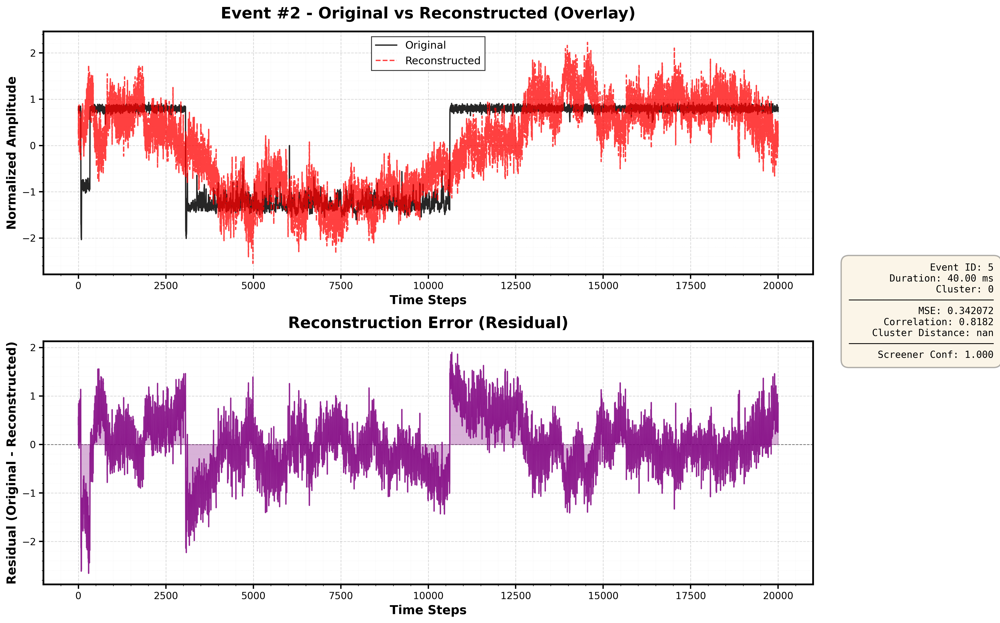

DETAILED RECONSTRUCTION ANALYSIS - Event #2

📊 Event Details:
   Event ID: 5
   Start Time: 325.00 ms
   Duration: 40.00 ms
   Cluster: 0

📈 Reconstruction Quality:
   MSE: 0.342072
   Correlation: 0.8182
   Max Residual: 2.6565
   Mean Residual: -0.015410
   Std Residual: 0.584666

🎯 Classification:
   Cluster ID: 0
   Distance to Centroid: nan
   Screener Confidence: 1.000

✅ Quality Assessment:
   Status: POOR reconstruction ⚠️


In [ ]:
##############################################
# Visualize Event Reconstruction (Publication Quality)
# ========== ALL PARAMETERS HERE ==========
##############################################

# --- Figure Dimensions & Resolution ---
FIGURE_DPI = 300                             # Resolution: 100-600
FIGURE_SIZE = (16, 10)                       # (width, height) in inches

# --- Line Styling ---
LINE_WIDTH_ORIGINAL = 1.5                    # Original waveform thickness
LINE_WIDTH_RECONSTRUCTED = 1.5               # Reconstructed waveform thickness
LINE_WIDTH_RESIDUAL = 1.5                    # Residual line thickness
LINE_WIDTH_GRID = 0.8                        # Grid line thickness

# --- Colors ---
COLOR_ORIGINAL = 'black'                     # Original waveform color
COLOR_RECONSTRUCTED = 'red'                  # Reconstructed waveform color
COLOR_RESIDUAL = 'purple'                    # Residual color
COLOR_GRID = 'gray'                          # Grid color
ALPHA_ORIGINAL = 0.85                        # Original transparency (0.0-1.0)
ALPHA_RECONSTRUCTED = 0.75                   # Reconstructed transparency (0.0-1.0)
ALPHA_RESIDUAL = 0.8                         # Residual transparency (0.0-1.0)
ALPHA_RESIDUAL_FILL = 0.3                    # Residual fill transparency (0.0-0.5)

# --- Font Sizes ---
FONT_SIZE_TITLE = 18                         # Subplot titles (16-24)
FONT_SIZE_AXES = 14                          # Axis labels (12-18)
FONT_SIZE_LEGEND = 12                        # Legend text (11-15)
FONT_SIZE_INFO = 11                          # Info box text (9-13)
FONT_SIZE_TICKS = 11                         # Tick labels (10-14)

# --- Spine & Grid Styling ---
SPINE_WIDTH = 2.0                            # Border thickness (1.5-3.0)
SPINE_COLOR = 'black'                        # Border color
TICK_WIDTH = 1.5                             # Tick line thickness (1.0-2.5)
TICK_LENGTH = 5                              # Tick length in points (4-8)
GRID_ALPHA = 0.3                             # Grid transparency (0.1-0.5)
GRID_LINESTYLE = '--'                        # Grid line style: '-', '--', '-.', ':'

# --- Info Box Styling ---
INFO_BOX_FACECOLOR = 'wheat'                 # Background color
INFO_BOX_ALPHA = 0.3                         # Transparency (0.0-1.0)
INFO_BOX_EDGE_COLOR = 'black'                # Border color
INFO_BOX_EDGE_WIDTH = 1.5                    # Border width (0.5-3.0)

# --- Optional Settings ---
SHOW_MINOR_TICKS = True                      # Show minor grid lines

# ========== END OF PARAMETERS ==========
# ========== NO CHANGES NEEDED BELOW ==========

def plot_event_reconstruction(event_idx, final_events,
                             figure_size, dpi,
                             line_width_original, line_width_reconstructed, 
                             line_width_residual,
                             color_original, color_reconstructed, color_residual,
                             alpha_original, alpha_reconstructed, alpha_residual,
                             alpha_residual_fill,
                             font_size_title, font_size_axes, font_size_legend,
                             font_size_info, font_size_ticks,
                             spine_width, spine_color, tick_width, tick_length,
                             grid_alpha, grid_linestyle,
                             info_box_facecolor, info_box_alpha,
                             info_box_edge_color, info_box_edge_width,
                             show_minor_ticks):
    """
    Visualize original vs reconstructed waveform with publication-quality styling
    
    Args:
        event_idx: Index of the event to visualize
        final_events: List of event dictionaries
        [all styling parameters as defined above]
    """
    if event_idx >= len(final_events):
        print(f" Error: Event index {event_idx} out of range (max: {len(final_events)-1})")
        return
    
    event = final_events[event_idx]
    
    # Extract waveforms
    original = event['waveform_normalized']
    reconstructed = event['waveform_reconstructed']
    
    # Create figure with 2 subplots
    fig, axes = plt.subplots(2, 1, figsize=figure_size, dpi=dpi)
    
    # Time axis (in samples)
    time_steps = np.arange(len(original))
    
    # ========== SUBPLOT 1: OVERLAY COMPARISON ==========
    ax1 = axes[0]
    
    # Plot waveforms
    ax1.plot(time_steps, original, linewidth=line_width_original, alpha=alpha_original, 
            label='Original', color=color_original, zorder=2)
    ax1.plot(time_steps, reconstructed, linewidth=line_width_reconstructed, alpha=alpha_reconstructed, 
            label='Reconstructed', color=color_reconstructed, linestyle='--', zorder=2)
    
    # === STYLING ===
    ax1.set_xlabel('Time Steps', fontsize=font_size_axes, fontweight='bold')
    ax1.set_ylabel('Normalized Amplitude', fontsize=font_size_axes, fontweight='bold')
    ax1.set_title(f'Event #{event_idx} - Original vs Reconstructed (Overlay)', 
                 fontsize=font_size_title, fontweight='bold', pad=15)
    
    # Make spines bold
    for spine in ax1.spines.values():
        spine.set_linewidth(spine_width)
        spine.set_color(spine_color)
    
    # Make ticks bold
    ax1.tick_params(axis='both', which='major', labelsize=font_size_ticks,
                   width=tick_width, length=tick_length, colors=spine_color)
    
    # Grid styling
    ax1.grid(True, which='major', alpha=grid_alpha, linestyle=grid_linestyle, 
            color='gray', linewidth=0.8)
    
    if show_minor_ticks:
        ax1.minorticks_on()
        ax1.grid(True, which='minor', alpha=grid_alpha*0.5, linestyle=':', 
                color='gray', linewidth=0.4)
    
    # Legend with bold font
    ax1.legend(fontsize=font_size_legend, loc='upper center', frameon=True,
              edgecolor=spine_color, fancybox=False, shadow=False)
    
    # ========== SUBPLOT 2: RESIDUAL ==========
    ax2 = axes[1]
    
    residual = original - reconstructed
    
    # Plot residual
    ax2.plot(time_steps, residual, linewidth=line_width_residual, color=color_residual, 
            alpha=alpha_residual, zorder=2)
    ax2.axhline(y=0, color=spine_color, linestyle='--', linewidth=0.8, alpha=0.6, zorder=1)
    ax2.fill_between(time_steps, residual, 0, alpha=alpha_residual_fill, color=color_residual, zorder=1)
    
    # === STYLING ===
    ax2.set_xlabel('Time Steps', fontsize=font_size_axes, fontweight='bold')
    ax2.set_ylabel('Residual (Original - Reconstructed)', fontsize=font_size_axes, fontweight='bold')
    ax2.set_title('Reconstruction Error (Residual)', fontsize=font_size_title, fontweight='bold', pad=15)
    
    # Make spines bold
    for spine in ax2.spines.values():
        spine.set_linewidth(spine_width)
        spine.set_color(spine_color)
    
    # Make ticks bold
    ax2.tick_params(axis='both', which='major', labelsize=font_size_ticks,
                   width=tick_width, length=tick_length, colors=spine_color)
    
    # Grid styling
    ax2.grid(True, which='major', alpha=grid_alpha, linestyle=grid_linestyle, 
            color='gray', linewidth=0.8)
    
    if show_minor_ticks:
        ax2.minorticks_on()
        ax2.grid(True, which='minor', alpha=grid_alpha*0.5, linestyle=':', 
                color='gray', linewidth=0.4)
    
    # ========== INFO BOX ==========
    
    info_text = (
        f"Event ID: {event['event_id']}\n"
        f"Duration: {event['duration_ms']:.2f} ms\n"
        f"Cluster: {event['cluster_id']}\n"
        f"─────────────────────────\n"
        f"MSE: {event['reconstruction_mse']:.6f}\n"
        f"Correlation: {event['reconstruction_corr']:.4f}\n"
        f"Cluster Distance: {event['cluster_distance']:.4f}\n"
        f"─────────────────────────\n"
        f"Screener Conf: {event['screener_confidence']:.3f}"
    )
    
    fig.text(0.99, 0.5, info_text, transform=fig.transFigure,
            fontsize=font_size_info, verticalalignment='center',
            horizontalalignment='right',
            bbox=dict(boxstyle='round,pad=0.8', facecolor=info_box_facecolor, 
                     alpha=info_box_alpha, edgecolor=info_box_edge_color, 
                     linewidth=info_box_edge_width),
            family='monospace')
    
    # ========== LAYOUT ==========
    plt.tight_layout(rect=[0, 0, 0.82, 1])  # Make room for info box
    
    plt.show()
    
    # ========== PRINT SUMMARY ==========
    print("="*70)
    print(f"DETAILED RECONSTRUCTION ANALYSIS - Event #{event_idx}")
    print("="*70)
    
    print(f"\n Event Details:")
    print(f"   Event ID: {event['event_id']}")
    print(f"   Start Time: {event['start_time_ms']:.2f} ms")
    print(f"   Duration: {event['duration_ms']:.2f} ms")
    print(f"   Cluster: {event['cluster_id']}")
    
    print(f"\n Reconstruction Quality:")
    print(f"   MSE: {event['reconstruction_mse']:.6f}")
    print(f"   Correlation: {event['reconstruction_corr']:.4f}")
    print(f"   Max Residual: {np.abs(residual).max():.4f}")
    print(f"   Mean Residual: {np.mean(residual):.6f}")
    print(f"   Std Residual: {np.std(residual):.6f}")
    
    print(f"\n Classification:")
    print(f"   Cluster ID: {event['cluster_id']}")
    print(f"   Distance to Centroid: {event['cluster_distance']:.4f}")
    print(f"   Screener Confidence: {event['screener_confidence']:.3f}")
    
    # Quality assessment
    print(f"\n Quality Assessment:")
    if event['reconstruction_mse'] < 0.01 and event['reconstruction_corr'] > 0.9:
        print("   Status: EXCELLENT reconstruction")
    elif event['reconstruction_mse'] < 0.05 and event['reconstruction_corr'] > 0.8:
        print("   Status: GOOD reconstruction ")
    elif event['reconstruction_mse'] < 0.1 and event['reconstruction_corr'] > 0.7:
        print("   Status: FAIR reconstruction ")
    else:
        print("   Status: POOR reconstruction ")


# ========== USAGE ==========
print("="*70)
print("VISUALIZE EVENT RECONSTRUCTION")
print("="*70)
print(f"\n Available events: 0 to {len(final_events)-1}")
print(f"\nUsage: plot_event_reconstruction(event_idx, final_events, ...parameters)")
print(f"\nQuick Example (using defaults):")

# Call with all parameters
plot_event_reconstruction(
    event_idx=2,
    final_events=final_events,
    figure_size=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    line_width_original=LINE_WIDTH_ORIGINAL,
    line_width_reconstructed=LINE_WIDTH_RECONSTRUCTED,
    line_width_residual=LINE_WIDTH_RESIDUAL,
    color_original=COLOR_ORIGINAL,
    color_reconstructed=COLOR_RECONSTRUCTED,
    color_residual=COLOR_RESIDUAL,
    alpha_original=ALPHA_ORIGINAL,
    alpha_reconstructed=ALPHA_RECONSTRUCTED,
    alpha_residual=ALPHA_RESIDUAL,
    alpha_residual_fill=ALPHA_RESIDUAL_FILL,
    font_size_title=FONT_SIZE_TITLE,
    font_size_axes=FONT_SIZE_AXES,
    font_size_legend=FONT_SIZE_LEGEND,
    font_size_info=FONT_SIZE_INFO,
    font_size_ticks=FONT_SIZE_TICKS,
    spine_width=SPINE_WIDTH,
    spine_color=SPINE_COLOR,
    tick_width=TICK_WIDTH,
    tick_length=TICK_LENGTH,
    grid_alpha=GRID_ALPHA,
    grid_linestyle=GRID_LINESTYLE,
    info_box_facecolor=INFO_BOX_FACECOLOR,
    info_box_alpha=INFO_BOX_ALPHA,
    info_box_edge_color=INFO_BOX_EDGE_COLOR,
    info_box_edge_width=INFO_BOX_EDGE_WIDTH,
    show_minor_ticks=SHOW_MINOR_TICKS
)

In [23]:
##############################################
# Plot Event Reconstructions (Publication Quality)
# ========== ALL PARAMETERS HERE ==========
##############################################

# --- Event Selection ---
PLOT_EVENT_INDICES = [2, 3, 11, 12, 13, 10]  # Which events to plot (0-indexed)

# --- Figure Dimensions & Resolution ---
FIGURE_DPI = 600                             # Resolution: 100-600 (higher = better quality)
FIGURE_SIZE = (20, 16)                       # (width, height) in inches

# --- Line Styling ---
LINE_WIDTH = 2.5                             # Line thickness (1.0-4.0)
COLORS_ORIGINAL = 'black'                    # Color for original waveforms
COLORS_RECONSTRUCTED = 'red'                 # Color for reconstructed waveforms

# --- Font Sizes ---
FONT_SIZE_TITLE = 25                         # Main title (18-35)
FONT_SIZE_AXES = 25                          # Axis labels (14-24)
FONT_SIZE_LEGEND = 16                        # Legend text (12-20)
FONT_SIZE_INFO = 15                          # Event info box (10-18)
FONT_SIZE_TICKS = 25                         # Tick labels (10-16)

# --- Y-Axis Settings ---
Y_MIN = -100                                 # Y-axis minimum (pA)
Y_MAX = 300                                  # Y-axis maximum (pA)
Y_INTERVAL = 100                              # Y-tick interval (pA)

# --- Spine & Grid Styling ---
SPINE_WIDTH = 2.5                            # Border thickness (1.5-3.5)
SPINE_COLOR = 'black'                        # Border color
TICK_WIDTH = 2.0                             # Tick line thickness (1.0-3.0)
TICK_LENGTH = 6                              # Tick length in points (4-10)
GRID_ALPHA = 0.3                             # Grid transparency (0.1-0.5)

# --- File Output ---
SAVE_PATH = 'reconstruction_grid_120mV.png'        # Output filename (or None to skip saving)
SAVE_FORMATS = ['png']                       # ['png', 'pdf', 'svg'] - formats to save

# --- Optional Settings ---
USE_ORIGINAL_SCALE = True                    # True: show pA scale | False: show normalized
SHOW_GRID = True                             # Show grid on plots
SHOW_EVENT_INFO = True                       # Show event info box

# ========== END OF PARAMETERS ==========
# ========== NO CHANGES NEEDED BELOW ==========

def plot_event_reconstruction_grid_shared_axes(final_events, event_indices, figure_size, dpi, 
                                               line_width, font_size_title, font_size_axes, 
                                               font_size_legend, font_size_info, font_size_ticks,
                                               save_path, save_formats,
                                               use_original_scale, y_min, y_max, y_interval,
                                               color_orig, color_recon, sample_rate,
                                               spine_width, spine_color, tick_width, tick_length,
                                               grid_alpha, show_grid, show_event_info):
    """Plot 3x2 grid with shared axes and professional styling"""
    
    if len(event_indices) == 0:
        print(" No events to plot")
        return
    
    if len(event_indices) > 6:
        print(f" Max 6 events. Using first 6.")
        event_indices = event_indices[:6]
    
    # Create 3x2 grid with shared axes
    fig, axes = plt.subplots(3, 2, figsize=figure_size, dpi=dpi, 
                            sharex=True, sharey=True)
    axes = axes.flatten()
    
    # Plot each event
    for plot_idx, event_idx in enumerate(event_indices):
        if event_idx >= len(final_events):
            print(f" Event {event_idx} out of range")
            continue
        
        event = final_events[event_idx]
        
        # Get waveforms
        original_norm = event['waveform_normalized']
        reconstructed_norm = event['waveform_reconstructed']
        
        # Convert to original scale if requested
        if use_original_scale:
            wf_mean = event['wf_mean']
            wf_std = event['wf_std']
            original = original_norm * wf_std + wf_mean
            reconstructed = reconstructed_norm * wf_std + wf_mean
        else:
            original = original_norm
            reconstructed = reconstructed_norm
        
        # Time axis in milliseconds
        time_ms = (np.arange(len(original)) / sample_rate) * 1000
        # Time axis in milliseconds (use actual event duration)
        #time_ms = np.linspace(0, event['duration_ms'], len(original))

        
        # Get subplot
        ax = axes[plot_idx]
        
        # Plot waveforms
        ax.plot(time_ms, original, linewidth=line_width, alpha=0.85, 
                color=color_orig, label='Original')
        ax.plot(time_ms, reconstructed, linewidth=line_width, alpha=0.75, 
                linestyle='--', color=color_recon, label='Reconstructed')
        
        # Set y-axis limits and ticks
        ax.set_ylim(y_min, y_max)
        y_ticks = np.arange(y_min, y_max + y_interval, y_interval)
        ax.set_yticks(y_ticks)
        
        # Make borders bold
        for spine in ax.spines.values():
            spine.set_linewidth(spine_width)
            spine.set_color(spine_color)
        
        # Make ticks bold
        ax.tick_params(axis='both', which='major', labelsize=font_size_ticks,
                      width=tick_width, length=tick_length, colors=spine_color)
        
        # Grid styling
        if show_grid:
            ax.grid(True, alpha=grid_alpha, linestyle='--', color='gray')
        
        # Add event info box
        if show_event_info:
            mse = event['reconstruction_mse']
            corr = event['reconstruction_corr']
            info_text = f"Event #{event_idx}\nMSE: {mse:.4f} | r: {corr:.3f}"
            ax.text(0.70, 0.20, info_text, transform=ax.transAxes,
                   fontsize=font_size_info, va='top', ha='left',
                   bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3, edgecolor='black', linewidth=1))
        
        # Only show y-axis label on leftmost plots
        if plot_idx % 2 == 0:
            ax.tick_params(labelleft=True)
        else:
            ax.tick_params(labelleft=False)
        
        # Only show x-axis label on bottom plots
        if plot_idx >= 4:
            ax.tick_params(labelbottom=True)
        else:
            ax.tick_params(labelbottom=False)
    
    # Add shared axis labels with bold font
    if use_original_scale:
        y_label = 'Current (pA)'
    else:
        y_label = 'Normalized Amplitude'
    
    fig.text(0.04, 0.5, y_label, va='center', rotation='vertical', 
            fontsize=font_size_axes, fontweight='bold')
    fig.text(0.5, 0.04, 'Time (ms)', ha='center', 
            fontsize=font_size_axes, fontweight='bold')
    
    # Main title
    fig.suptitle('Event Reconstruction Comparison', 
                fontsize=font_size_title, fontweight='bold', y=0.985)
    
    # Add legend at the top
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color=color_orig, linewidth=line_width, 
               label='Original', alpha=0.85),
        Line2D([0], [0], color=color_recon, linewidth=line_width, 
               linestyle='--', label='Reconstructed', alpha=0.75)
    ]
    
    fig.legend(handles=legend_elements, 
              loc='upper center', 
              bbox_to_anchor=(0.5, 0.97),
              ncol=2, 
              fontsize=font_size_legend,
              frameon=False)
    
    plt.tight_layout(rect=[0.06, 0.06, 1, 0.95])
    
    # Save in requested formats
    if save_path:
        for fmt in save_formats:
            output_file = save_path.replace('.png', f'.{fmt}')
            plt.savefig(output_file, dpi=dpi, bbox_inches='tight', format=fmt)
            print(f" Saved: {output_file}")
    
    plt.show()
    
    # Print summary
    print("\n" + "="*70)
    print("RECONSTRUCTION SUMMARY")
    print("="*70)
    for event_idx in event_indices:
        if event_idx < len(final_events):
            e = final_events[event_idx]
            print(f"Event #{event_idx}: Duration={e['duration_ms']:.2f}ms | "
                  f"Cluster={e['cluster_id']} | MSE={e['reconstruction_mse']:.5f} | "
                  f"Corr={e['reconstruction_corr']:.4f}")


# ========== RUN ==========
plot_event_reconstruction_grid_shared_axes(
    final_events=final_events,
    event_indices=PLOT_EVENT_INDICES,
    figure_size=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    line_width=LINE_WIDTH,
    font_size_title=FONT_SIZE_TITLE,
    font_size_axes=FONT_SIZE_AXES,
    font_size_legend=FONT_SIZE_LEGEND,
    font_size_info=FONT_SIZE_INFO,
    font_size_ticks=FONT_SIZE_TICKS,
    save_path=SAVE_PATH,
    save_formats=SAVE_FORMATS,
    use_original_scale=USE_ORIGINAL_SCALE,
    y_min=Y_MIN,
    y_max=Y_MAX,
    y_interval=Y_INTERVAL,
    color_orig=COLORS_ORIGINAL,
    color_recon=COLORS_RECONSTRUCTED,
    sample_rate=sample_rate,
    spine_width=SPINE_WIDTH,
    spine_color=SPINE_COLOR,
    tick_width=TICK_WIDTH,
    tick_length=TICK_LENGTH,
    grid_alpha=GRID_ALPHA,
    show_grid=SHOW_GRID,
    show_event_info=SHOW_EVENT_INFO
)

 Saved: reconstruction_grid_120mV.png



RECONSTRUCTION SUMMARY
Event #2: Duration=40.00ms | Cluster=0 | MSE=0.34207 | Corr=0.8182
Event #3: Duration=30.00ms | Cluster=0 | MSE=0.70123 | Corr=0.7637
Event #11: Duration=30.00ms | Cluster=0 | MSE=0.49335 | Corr=0.7889
Event #12: Duration=13.46ms | Cluster=0 | MSE=0.21250 | Corr=0.8886
Event #13: Duration=0.84ms | Cluster=0 | MSE=0.04811 | Corr=0.9794
Event #10: Duration=20.00ms | Cluster=0 | MSE=0.39219 | Corr=0.8206


## Results Summary & Export

### What gets exported

- CSV: Tabular results for quick inspection and spreadsheets.
- Pickle: Full event details including waveforms for programmatic reuse.
- Optional parquet: Efficient storage if you need large-scale analytics.

In [24]:
##############################################
# Create Results DataFrame
##############################################

# Convert to DataFrame (excluding array columns for display)
results_df = pd.DataFrame([{
    'event_id': e['event_id'],
    'start_sample': e['start_sample'],
    'end_sample': e['end_sample'],
    'start_time_ms': e['start_time_ms'],
    'duration_ms': e['duration_ms'],
    'cluster_id': e['cluster_id'],
    'screener_confidence': e['screener_confidence'],
    'reconstruction_mse': e['reconstruction_mse'],
    'reconstruction_corr': e['reconstruction_corr'],
    'cluster_distance': e['cluster_distance'],
    'nearest_train_distance': e.get('nearest_train_distance', np.nan),
    'nearest_train_cluster': e.get('nearest_train_cluster', -1),
    'cluster_match': e.get('cluster_match', False),
    'is_outlier': e.get('is_outlier', False)
} for e in final_events])

print("="*70)
print("FINAL RESULTS SUMMARY")
print("="*70)

print(f"\n📊 Overall Statistics:")
print(f"   Total events detected: {len(final_events)}")
print(f"   Mean duration: {results_df['duration_ms'].mean():.2f} ms")
print(f"   Mean reconstruction MSE: {results_df['reconstruction_mse'].mean():.6f}")
print(f"   Mean reconstruction corr: {results_df['reconstruction_corr'].mean():.4f}")

# Show comparison statistics if available
if 'nearest_train_distance' in results_df.columns and not results_df['nearest_train_distance'].isna().all():
    print(f"\n📊 Training Comparison:")
    print(f"   Mean distance to training: {results_df['nearest_train_distance'].mean():.4f}")
    print(f"   Cluster matches: {results_df['cluster_match'].sum()} / {len(final_events)} ({results_df['cluster_match'].sum()/len(final_events)*100:.1f}%)")
    print(f"   Outliers: {results_df['is_outlier'].sum()} ({results_df['is_outlier'].sum()/len(final_events)*100:.1f}%)")

print(f"\n📊 Events per Cluster:")
for cluster_id in range(n_clusters):
    cluster_count = (results_df['cluster_id'] == cluster_id).sum()
    print(f"   Cluster {cluster_id}: {cluster_count} events ({cluster_count/len(final_events)*100:.1f}%)")

# Display first few events
print(f"\n📋 First 10 Events:")
display(results_df.head(10))

FINAL RESULTS SUMMARY

📊 Overall Statistics:
   Total events detected: 2265
   Mean duration: 20.29 ms
   Mean reconstruction MSE: 0.302787
   Mean reconstruction corr: 0.8652

📊 Training Comparison:
   Mean distance to training: 60.7000
   Cluster matches: 0 / 2265 (0.0%)
   Outliers: 30 (1.3%)

📊 Events per Cluster:
   Cluster 0: 2265 events (100.0%)
   Cluster 1: 0 events (0.0%)
   Cluster 2: 0 events (0.0%)
   Cluster 3: 0 events (0.0%)

📋 First 10 Events:


,event_id,start_sample,end_sample,start_time_ms,duration_ms,cluster_id,screener_confidence,reconstruction_mse,reconstruction_corr,cluster_distance,nearest_train_distance,nearest_train_cluster,cluster_match,is_outlier
0,0,5000,40000,5.000,35.000,0,0.999966,0.625544,0.804272,NaN,82.455476,4,False,False
1,1,136009,136863,136.009,0.854,0,0.703624,0.051570,0.980261,NaN,40.429612,3,False,False
2,5,325000,365000,325.000,40.000,0,0.999954,0.342072,0.818160,NaN,63.366849,4,False,False
3,6,500000,530000,500.000,30.000,0,0.990261,0.701233,0.763678,NaN,98.400567,6,False,False
4,7,583630,585593,583.630,1.963,0,0.993333,0.035548,0.984425,NaN,36.723409,8,False,False
5,8,597083,603042,597.083,5.959,0,0.993333,0.140184,0.939390,NaN,24.145975,5,False,False
6,9,1062613,1082579,1062.613,19.966,0,0.999966,0.357497,0.802153,NaN,61.847033,1,False,False
7,10,1085660,1087276,1085.660,1.616,0,0.999966,0.117745,0.983550,NaN,68.994628,8,False,False
8,11,1095000,1120000,1095.000,25.000,0,0.999871,0.139216,0.927942,NaN,56.862657,6,False,False
9,12,1125000,1160000,1125.000,35.000,0,0.959130,0.549250,0.710809,NaN,89.362439,4,False,False


In [ ]:
##############################################
# Export Results
##############################################

# Save to CSV
#output_csv = 'detected_events_results_100mV.csv'
output_csv = 'detected_events_results_100mV.csv'
results_df.to_csv(output_csv, index=False)
print(f"\n💾 Results saved to: {output_csv}")

# Save detailed data to pickle (includes waveforms)
import pickle
output_pickle = 'detected_events_detailed.pkl'
with open(output_pickle, 'wb') as f:
    pickle.dump(final_events, f)
print(f"💾 Detailed data saved to: {output_pickle}")

# Save to parquet (optional, more efficient)
# output_parquet = 'detected_events_results.parquet'
# results_df.to_parquet(output_parquet, index=False)
# print(f"💾 Results saved to: {output_parquet}")

print(f"\n✅ Export complete!")

## Visualize Results by Cluster

### Why visualize by cluster?

- Quickly assess intra-cluster consistency of waveforms.
- Spot rare/heterogeneous clusters that may require separate handling.
- Use `n_samples_per_cluster` to adjust preview density.

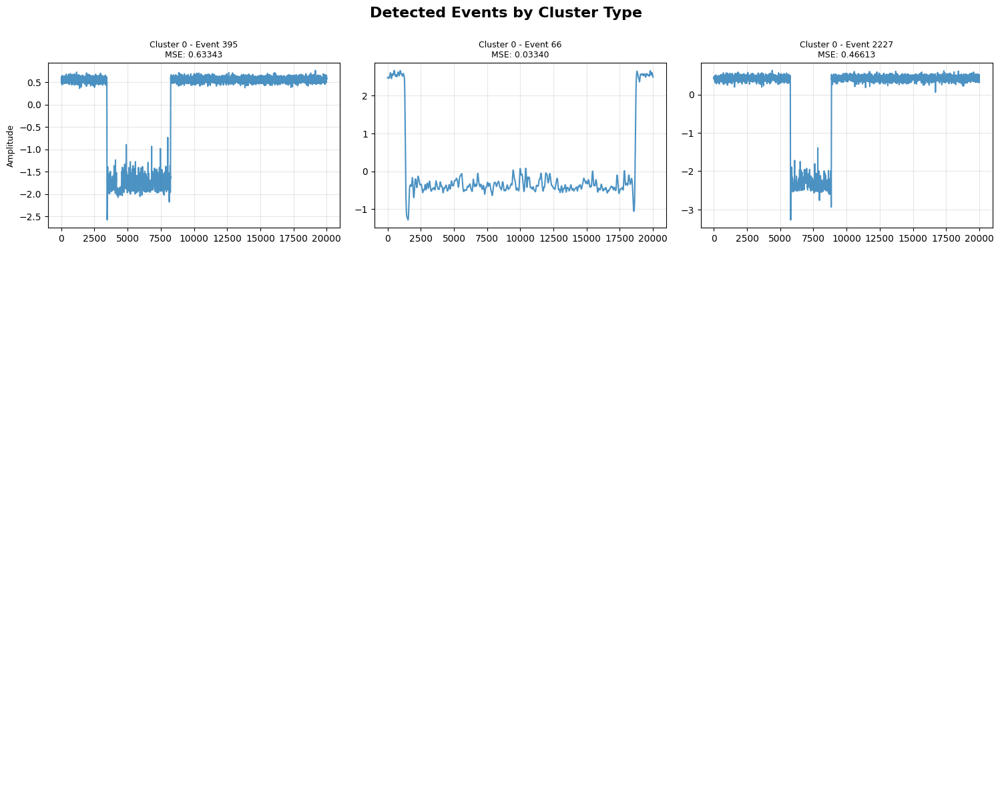

In [25]:
##############################################
# Visualize Events by Cluster
##############################################

# Plot sample events from each cluster
n_samples_per_cluster = 3

fig, axes = plt.subplots(n_clusters, n_samples_per_cluster, figsize=(15, 3*n_clusters))
if n_clusters == 1:
    axes = axes.reshape(1, -1)

colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))

for cluster_id in range(n_clusters):
    cluster_events = [e for e in final_events if e['cluster_id'] == cluster_id]
    
    # Sample random events from this cluster
    n_to_sample = min(n_samples_per_cluster, len(cluster_events))
    sampled_events = np.random.choice(cluster_events, n_to_sample, replace=False) if len(cluster_events) > 0 else []
    
    for j, event in enumerate(sampled_events):
        ax = axes[cluster_id, j]
        
        # Plot normalized waveform
        ax.plot(event['waveform_normalized'], linewidth=1.5, color=colors[cluster_id], alpha=0.8)
        ax.set_title(f"Cluster {cluster_id} - Event {event['event_id']}\nMSE: {event['reconstruction_mse']:.5f}", fontsize=9)
        ax.grid(True, alpha=0.3)
        
        if j == 0:
            ax.set_ylabel('Amplitude', fontsize=9)
        if cluster_id == n_clusters - 1:
            ax.set_xlabel('Time Steps', fontsize=9)
    
    # Hide unused subplots
    for j in range(n_to_sample, n_samples_per_cluster):
        axes[cluster_id, j].axis('off')

plt.suptitle('Detected Events by Cluster Type', fontsize=16, fontweight='bold', y=1.001)
plt.tight_layout()
plt.show()